## EDA Summary - Key Findings

1. **Geographic gradient**: Bloom rate ranges from 46% in western LIS (station A2) 
   to 1.7% in eastern LIS (station N3). Western stations near urban runoff sources 
   are consistently highest risk.

2. **Long-term decline**: Bloom frequency has declined at -0.63%/year since 1993, 
   with a sharp inflection after 2014, likely linked to Connecticut's nitrogen 
   reduction programs.

3. **Cold water blooms**: Contrary to expectation, bloom frequency peaks in 
   February-March at water temperatures of 0-5°C, suggesting nutrient-driven 
   spring blooms dominate over temperature-driven summer blooms.

4. **2002 anomaly**: Bloom rate spiked to 61% in 2002, the highest in the 32-year 
   record. Warrants further investigation.

5. **Seasonal variability**: Winter and Spring show highest chlorophyll variance, 
   Fall is most stable.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("../data/hab_labels_lis.csv")
df['time'] = pd.to_datetime(df['time'], utc=True)
df['year'] = df['time'].dt.year
df['month'] = df['time'].dt.month
df['season'] = df['month'].map({
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Fall', 10: 'Fall', 11: 'Fall'
})

print(f"Total records: {len(df):,}")
print(f"Date range: {df['time'].min()} to {df['time'].max()}")
print(f"Unique stations: {df['station_name'].nunique()}")
print(f"Bloom rate: {df['bloom'].mean()*100:.1f}%")

FileNotFoundError: [Errno 2] No such file or directory: '../data/hab_labels_lis.csv'

In [ ]:
# Bloom rate by station
station_stats = df.groupby('station_name').agg(
    total=('bloom', 'count'),
    blooms=('bloom', 'sum'),
    mean_chl=('Chlorophyll', 'mean'),
    lat=('latitude', 'first'),
    lon=('longitude', 'first')
).reset_index()

station_stats['bloom_rate'] = station_stats['blooms'] / station_stats['total'] * 100
station_stats = station_stats.sort_values('bloom_rate', ascending=False)

print(station_stats[['station_name', 'total', 'bloom_rate', 'mean_chl', 'lat', 'lon']].head(15).to_string())

   station_name  total  bloom_rate   mean_chl        lat        lon
32           A2     54   46.296296  18.764815  40.800835 -73.787330
3            04  12224   40.027814  10.370492  40.937830 -73.519330
6            07  12038   39.333776  10.189635  40.950333 -73.425330
1            02  15744   37.836636  10.114451  40.934666 -73.600670
33           A4  81276   35.486490  11.385802  40.872500 -73.734170
34           B3  43277   35.286642  11.055334  40.918335 -73.642830
0            01  15570   34.810533   9.886046  40.963333 -73.623665
4            05  13699   32.104533   9.608217  41.009335 -73.513664
13           15  34377   29.342293   9.492542  40.931330 -73.221170
5            06  17713   28.843222   8.516593  40.961166 -73.476670
10           12   9383   28.636897   8.877195  41.108665 -73.253000
9            10  15907   27.956246   8.655191  40.951668 -73.332500
35           C1  46718   27.278565   8.991318  40.955833 -73.580330
14           16   8128   26.648622   9.001241  4

In [ ]:
# Sort by lowest bloom rate
print(station_stats[['station_name', 'total', 'bloom_rate', 'mean_chl', 'lat', 'lon']].tail(15).to_string())

   station_name  total  bloom_rate  mean_chl        lat        lon
17           20  16765   16.301819  6.209064  40.994000 -73.042336
23           27  12348   15.338516  5.722380  41.158670 -72.849500
42           H4  50075   14.797803  5.740163  41.101665 -72.934000
16           19  18412   14.582881  5.473245  41.055332 -73.080830
19           22  18871   14.344762  5.267338  41.082333 -73.022835
38           E1  84588   14.147397  5.488309  41.019333 -73.291336
40           F3  87489   12.680451  5.273964  41.017834 -73.144500
24           28  11720   12.474403  4.530982  41.078167 -72.833500
44           I2  53826   11.672798  5.302490  41.137500 -72.655000
45           J2  34641   10.799342  5.439606  41.182000 -72.457664
43           H6  84227   10.503758  4.741427  41.026000 -72.913500
46           J4   1090    8.165138  6.413496  41.097500 -72.450000
47           K2  63492    5.907831  4.058809  41.234333 -72.265830
48           M3  66175    4.692104  3.908718  41.237167 -72.05

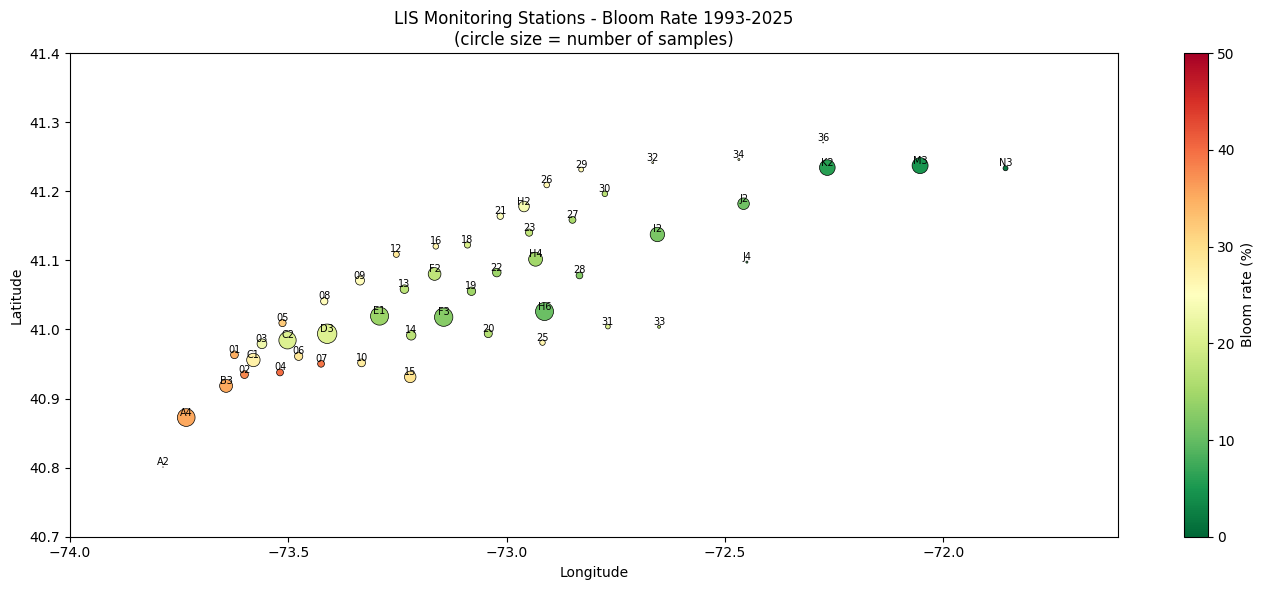

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

scatter = ax.scatter(
    station_stats['lon'],
    station_stats['lat'],
    c=station_stats['bloom_rate'],
    s=station_stats['total']/500,
    cmap='RdYlGn_r',
    vmin=0, vmax=50,
    edgecolors='black',
    linewidth=0.5
)

plt.colorbar(scatter, ax=ax, label='Bloom rate (%)')

for _, row in station_stats.iterrows():
    ax.annotate(row['station_name'], 
                (row['lon'], row['lat']),
                fontsize=7, ha='center', va='bottom')

ax.set_title('LIS Monitoring Stations - Bloom Rate 1993-2025\n(circle size = number of samples)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_xlim(-74.0, -71.6)
ax.set_ylim(40.7, 41.4)
plt.tight_layout()
plt.savefig('../figures/eda/station_bloom_rates.png', dpi=150)
plt.show()

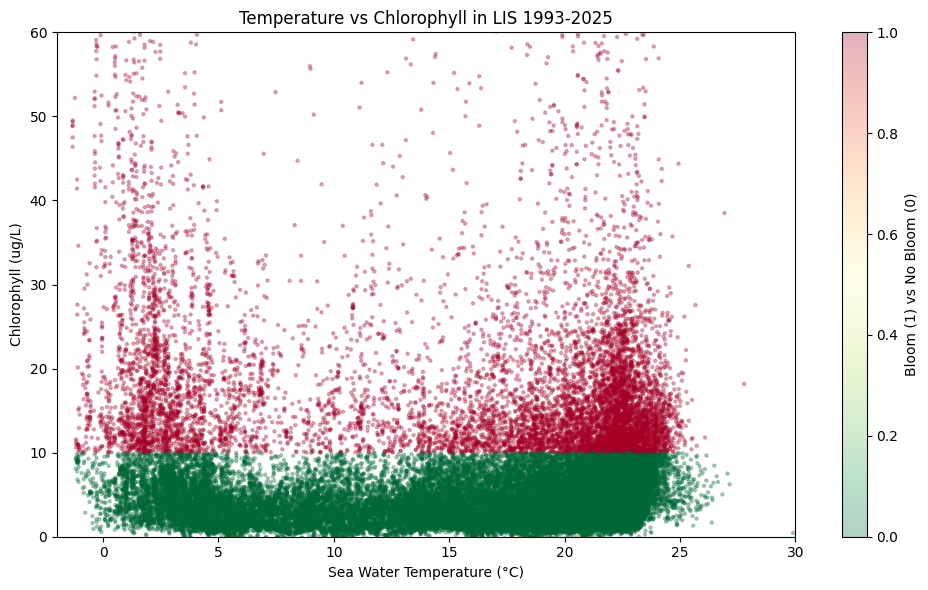

In [ ]:
# Sample 50k points so it doesn't take forever to plot
sample = df[df['sea_water_temperature'].notna() & df['Chlorophyll'].notna()].sample(50000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    sample['sea_water_temperature'],
    sample['Chlorophyll'],
    c=sample['bloom'],
    cmap='RdYlGn_r',
    alpha=0.3,
    s=5
)

ax.set_xlim(-2, 30)
ax.set_ylim(0, 60)
ax.set_xlabel('Sea Water Temperature (°C)')
ax.set_ylabel('Chlorophyll (ug/L)')
ax.set_title('Temperature vs Chlorophyll in LIS 1993-2025')
plt.colorbar(scatter, ax=ax, label='Bloom (1) vs No Bloom (0)')
plt.tight_layout()
plt.savefig('../figures/eda/temp_vs_chl.png', dpi=150)
plt.show()

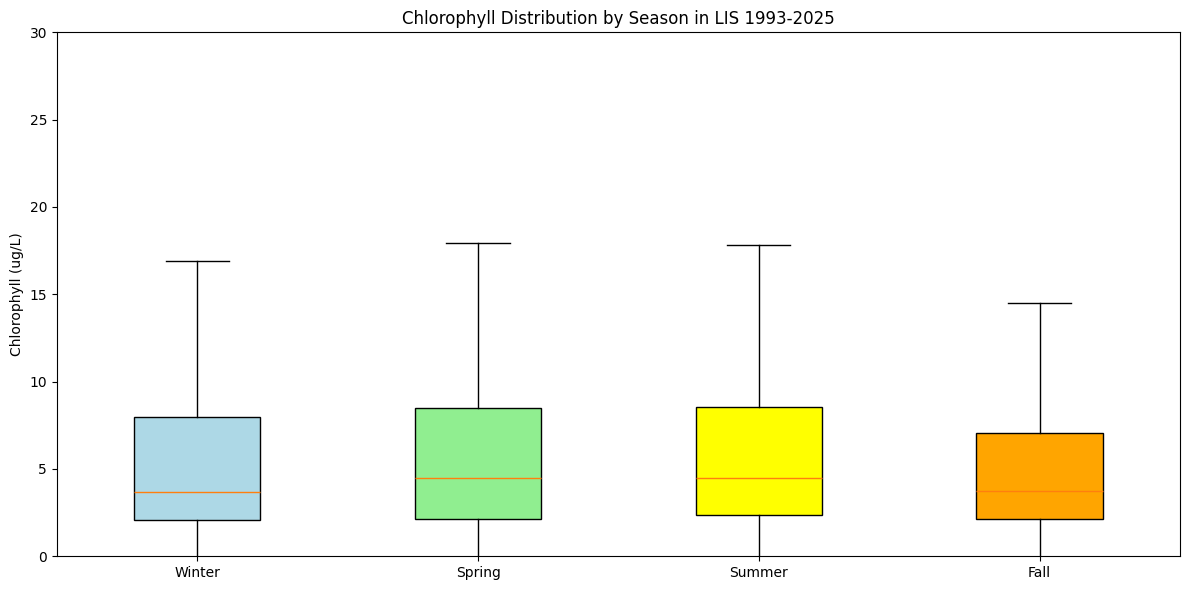

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

seasons = ['Winter', 'Spring', 'Summer', 'Fall']
season_data = [df[df['season'] == s]['Chlorophyll'].dropna() for s in seasons]

bp = ax.boxplot(season_data, tick_labels=seasons, patch_artist=True,
                showfliers=False)

colors = ['lightblue', 'lightgreen', 'yellow', 'orange']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Chlorophyll Distribution by Season in LIS 1993-2025')
ax.set_ylabel('Chlorophyll (ug/L)')
ax.set_ylim(0, 30)
plt.tight_layout()
plt.savefig('../figures/eda/seasonal_chl_distribution.png', dpi=150)
plt.show()

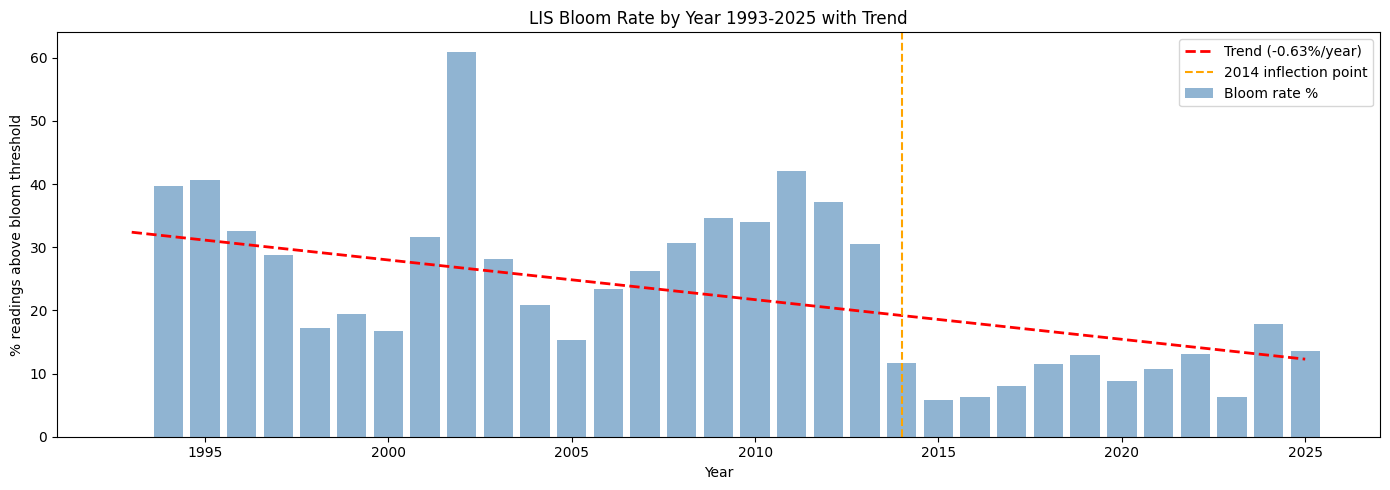

Overall trend: -0.63% per year


In [ ]:
yearly = df.groupby('year').agg(
    bloom_rate=('bloom', 'mean'),
    mean_chl=('Chlorophyll', 'mean')
).reset_index()

# Fit trend lines
z1 = np.polyfit(yearly['year'], yearly['bloom_rate']*100, 1)
p1 = np.poly1d(z1)

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(yearly['year'], yearly['bloom_rate']*100, color='steelblue', alpha=0.6, label='Bloom rate %')
ax.plot(yearly['year'], p1(yearly['year']), 'r--', linewidth=2, label=f'Trend ({z1[0]:+.2f}%/year)')
ax.axvline(x=2014, color='orange', linestyle='--', linewidth=1.5, label='2014 inflection point')

ax.set_title('LIS Bloom Rate by Year 1993-2025 with Trend')
ax.set_ylabel('% readings above bloom threshold')
ax.set_xlabel('Year')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/eda/bloom_trend.png', dpi=150)
plt.show()

print(f"Overall trend: {z1[0]:+.2f}% per year")

In [ ]:
# Load nutrient data
nutrients = pd.read_csv("../data/DEEP_Nutrient_3880_f140_a610.csv", low_memory=False, skiprows=[1])
print(f"Shape: {nutrients.shape}")
print(f"Columns: {list(nutrients.columns)}")
print(f"\nUnique parameters: {nutrients['Parameter'].unique()}")

Shape: (204292, 24)
Columns: ['cruise', 'Lab_ID', 'Station_Name', 'Depth_Code', 'Detection_Limit', 'Dilution_Factor', 'PQL', 'Parameter', 'Result', 'non_detect', 'Units', 'Comment', 'Month', 'latitude', 'longitude', 'Time_ON_Station', 'Time_OFF_Station', 'time', 'Start_Date', 'End_Date', 'B_Sample_Depth', 'M_Sample_Depth', 'S_Sample_Depth', 'NB_Sample_Depth']

Unique parameters: <StringArray>
[     'DOC',      'DIP',       'PC',   'NOX-LC',     'CHLA', 'BIOSI-LC',
      'TSS',    'PP-LC',  'SIO2-LC',       'PN',   'NH#-LC', '-MLS-FLT',
 '-REC-VOL', '-RECVOLB',   'TDN-LC',      'TDP', '-MLSFLTB', '-CHLARAW',
  'CHLA0.5']
Length: 19, dtype: str


In [ ]:
# Filter to key parameters
key_params = ['NOX-LC', 'DIP', 'NH#-LC', 'CHLA', 'TDN-LC']
nuts = nutrients[nutrients['Parameter'].isin(key_params)].copy()

# Clean up
nuts['Result'] = pd.to_numeric(nuts['Result'], errors='coerce')
nuts['latitude'] = pd.to_numeric(nuts['latitude'], errors='coerce')
nuts['longitude'] = pd.to_numeric(nuts['longitude'], errors='coerce')
nuts['time'] = pd.to_datetime(nuts['time'], errors='coerce', utc=True)
nuts['date'] = nuts['time'].dt.date

# Pivot so each parameter becomes a column
nuts_pivot = nuts.pivot_table(
    index=['date', 'Station_Name', 'latitude', 'longitude'],
    columns='Parameter',
    values='Result',
    aggfunc='mean'
).reset_index()

nuts_pivot.columns.name = None
print(f"Shape: {nuts_pivot.shape}")
print(nuts_pivot.head())

Shape: (6951, 9)
         date Station_Name   latitude  longitude   CHLA       DIP    NH#-LC  \
0  1991-01-30           F3  41.017834  -73.14450  4.975  0.045950  0.031000   
1  1991-01-30           H6  41.026000  -72.91350  5.595  0.044700  0.034500   
2  1991-01-30           I2  41.137500  -72.65500  4.015  0.042550  0.057500   
3  1991-01-30           M3  41.237167  -72.05334  1.120  0.033833  0.052667   
4  1991-02-20           F3  41.017834  -73.14450  4.970  0.035700  0.006500   

     NOX-LC    TDN-LC  
0  0.240000  0.385000  
1  0.235000  0.370000  
2  0.230000  0.410000  
3  0.206667  0.393333  
4  0.130000  0.305000  


In [ ]:
# Merge nutrients into main labels
df['date'] = df['time'].dt.date

merged = df.merge(
    nuts_pivot,
    left_on=['date', 'station_name'],
    right_on=['date', 'Station_Name'],
    how='left'
)

print(f"Original records: {len(df)}")
print(f"After merge: {len(merged)}")
print(f"Records with NOX-LC: {merged['NOX-LC'].notna().sum()}")
print(f"Records with DIP: {merged['DIP'].notna().sum()}")

# Quick correlation check
print("\nCorrelation with bloom label:")
for col in ['NOX-LC', 'DIP', 'NH#-LC', 'TDN-LC', 'sea_water_temperature', 'sea_water_salinity']:
    if col in merged.columns:
        corr = merged[col].corr(merged['bloom'])
        print(f"  {col}: {corr:.3f}")

Original records: 1358852
After merge: 1358852
Records with NOX-LC: 739458
Records with DIP: 764170

Correlation with bloom label:
  NOX-LC: -0.096
  DIP: -0.085
  NH#-LC: 0.044
  TDN-LC: 0.002
  sea_water_temperature: -0.004
  sea_water_salinity: -0.193


## Nutrient Analysis Findings

- Salinity is the strongest single predictor (r = -0.193): low salinity 
  indicates freshwater/nutrient input from rivers
- Nitrogen and phosphorus show weak negative correlation with blooms, 
  likely due to nutrient depletion during active blooms
- This suggests nutrients must be measured as LAGGED features (7-14 days 
  prior) rather than same-day measurements
- Temperature alone is not predictive (r = -0.004)

In [ ]:
merged.to_csv("../data/hab_labels_with_nutrients.csv", index=False)
print("Saved.")

Saved.


In [ ]:
# Compute climatological baseline
climatology = df.groupby(['station_name', 'month'])['Chlorophyll'].mean().reset_index()
climatology.columns = ['station_name', 'month', 'chl_climatology']

merged2 = merged.merge(climatology, on=['station_name', 'month'], how='left')
merged2['chl_anomaly'] = merged2['Chlorophyll'] - merged2['chl_climatology']
merged2['chl_anomaly_pct'] = (merged2['chl_anomaly'] / merged2['chl_climatology']) * 100

print(f"Anomaly correlation with bloom: {merged2['chl_anomaly'].corr(merged2['bloom']):.3f}")
print(f"Raw CHL correlation with bloom: {merged2['Chlorophyll'].corr(merged2['bloom']):.3f}")

merged2.to_csv("../data/hab_labels_final.csv", index=False)
print("Saved.")

Anomaly correlation with bloom: 0.634
Raw CHL correlation with bloom: 0.707
Saved.
